# 📊 TickerMiner
Notebook de Analisis Exploratorio de Datos (EDA)

## Preliminares

In [1]:
import pandas as pd

from src.modeling import (
    cargar_datos_clean, filtrar_pares_restantes, separar_datos_live,
    categorizar_en_cuantiles
    )
from src.transform import encontrar_columnas
from src.eda_utils import (
    mostrar_asimetrias, mostrar_missings, pintar_columna,
    top_correlaciones, pintar_violin_plots, top_correlaciones_objetivo
)

# Cargar fichero de precios
df_clean = cargar_datos_clean()

df_clean.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 931 entries, 2007-12-17 to 2026-11-02
Columns: 108 entries, EURUSD_intra_weekly to VIX_pct_chg_50d_yeo
dtypes: float64(108)
memory usage: 792.8 KB


In [2]:
# Missings
mostrar_missings(df_clean)

Series([], dtype: float64)

## Analisis de variables

In [19]:
# Descripcion de variables
columnas_clean = df_clean.columns.tolist()
cadena = "SPY_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)

df_clean[columnas].describe().T

,count,mean,std,min,25%,50%,75%,max
SPY_acceleration_zscore_lag1,931.0,-5.035342e-02,1.066431,-3.894018,-0.771400,-0.125359,0.566006,4.244353
SPY_return_zscore_lag1,931.0,1.090405e-01,1.077723,-7.730737,-0.431018,0.202159,0.759702,3.758216
SPY_return_skew_lag1,931.0,-3.528871e-01,0.546893,-2.992365,-0.794881,-0.249559,0.044186,0.866151
SPY_std_lag1_log,931.0,-3.940048e+00,0.394717,-4.965223,-4.221102,-3.984236,-3.658692,-2.811147
SPY_vol_directional_lag1_log,931.0,-1.836816e-01,0.366659,-1.877387,-0.424235,-0.211784,0.012736,1.779587
SPY_Volume_zscore_lag1_yeo,931.0,1.526408e-17,1.000537,-4.693655,-0.570349,-0.010393,0.604003,4.637778


In [4]:
# Asimetrias general
mostrar_asimetrias(df_clean)

VIX_level                           2.395178
USDCAD_std_lag1_log                 1.730749
EURUSD_return_skew_lag1             1.589679
USDCHF_std_lag1_log                 1.103859
Oil_vol_directional_lag1_log        0.971718
STLFSI_delta_50d                    0.953414
EURUSD_open_gap_zscore_yeo          0.811329
GBPUSD_std_lag1_log                 0.794907
Oil_std_lag1_log                    0.783695
VIX_level_skew                      0.776231
Real_yield_delta_50d                0.773677
EURUSD_gap_skew_lag1                0.749568
AUDUSD_vol_directional_lag1_log     0.572392
Oil_return_skew_lag1                0.532260
AUDUSD_sma15_pct_diff_sma50_lag1    0.497620
GBPUSD_vol_directional_lag1_log     0.434020
USDJPY_sma15_pct_diff_sma50_lag1    0.378803
AUDUSD_accel_diff_zscore_lag1       0.369585
SPY_acceleration_zscore_lag1        0.359065
USDJPY_gap_skew_lag1                0.351795
SPY_vol_directional_lag1_log        0.349885
GBPUSD_acceleration_zscore_lag1     0.282458
AUDUSD_std

In [5]:
# Asimetria por grupo
cadena = "_std_"
columnas = encontrar_columnas(columnas_target=columnas_clean, cadena=cadena)
mostrar_asimetrias(df_clean[columnas])

USDCAD_std_lag1_log    1.730749
USDCHF_std_lag1_log    1.103859
GBPUSD_std_lag1_log    0.794907
Oil_std_lag1_log       0.783695
AUDUSD_std_lag1_log    0.246301
SPY_std_lag1_log       0.192018
Gold_std_lag1_log      0.098101
EURUSD_std_lag1_log    0.097066
USDJPY_std_lag1_log   -0.259846


Cont


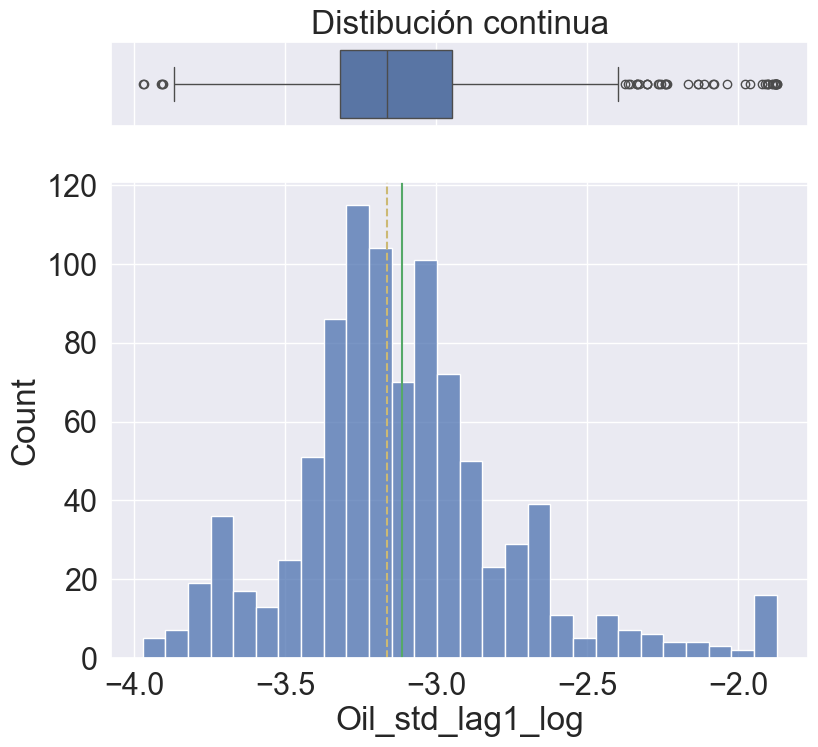

In [7]:
# Visualizar columna
col = 'Oil_std_lag1_log'
pintar_columna(df_clean[col])

## Correlaciones

In [8]:
# Tabla de Correlaciones general
top_correlaciones(df=df_clean, top_n=30)

,Variable A,Variable B,correlation
350,USDJPY_accel_diff_zscore_lag1,USDJPY_ret_diff_zscore_lag1,0.906543
170,GBPUSD_accel_diff_zscore_lag1,GBPUSD_ret_diff_zscore_lag1,0.889202
594,USDCAD_accel_diff_zscore_lag1,USDCAD_ret_diff_zscore_lag1,0.885022
902,USDCHF_accel_diff_zscore_lag1,USDCHF_ret_diff_zscore_lag1,0.881811
1274,AUDUSD_accel_diff_zscore_lag1,AUDUSD_ret_diff_zscore_lag1,0.870579
54,EURUSD_accel_diff_zscore_lag1,EURUSD_ret_diff_zscore_lag1,0.869155
1415,AUDUSD_sma15_pct_diff_sma50_lag1,USDCAD_sma15_pct_diff_sma50_lag1,0.842330
2275,USDCHF_gap_skew_lag1,GBPUSD_gap_skew_lag1,0.806214
1003,USDCHF_sma15_pct_diff_sma50_lag1,EURUSD_sma15_pct_diff_sma50_lag1,0.781493
3077,USDCHF_std_lag1_log,EURUSD_std_lag1_log,0.764824


In [13]:
# Correlaciones con la variable objetivo continua
simbolo_objetivo = 'USDJPY'
objetivo = f"{simbolo_objetivo}_intra_weekly"

top_correlaciones_objetivo(df=df_clean, target_col=objetivo)

,Variable,Correlación
0,USDCHF_intra_weekly,0.415070
1,EURUSD_intra_weekly,-0.353963
2,GBPUSD_intra_weekly,-0.215979
3,AUDUSD_intra_weekly,-0.209752
4,USDCAD_intra_weekly,0.109370
5,GBPUSD_std_lag1_log,-0.076765
6,EURUSD_gap_skew_lag1,-0.076513
7,USDJPY_open_gap_zscore_yeo,-0.070461
8,AUDUSD_std_lag1_log,-0.068851
9,EURUSD_open_gap_zscore_yeo,0.065956


## Analisis de label categorica

In [14]:
# Filtrar pares restantes
df_filtrado = filtrar_pares_restantes(df_clean,simbolo_objetivo)

# Separar datos de entrenamiento y test  
ultima_fecha = df_filtrado.index.max()
df_train, df_live = separar_datos_live(df=df_filtrado, fecha=ultima_fecha)

# Se crea la variable categorica a partir del dataset de entrenamiento
# Variable objetivo: se crea variable categorica por cuantiles

objetivo_cat = f"{objetivo}_cat"

df_train, tabla_bins = categorizar_en_cuantiles(
    df_train, 
    columna=objetivo, 
    num_cuantiles=3, 
    quitar_original=True
    )


print(f"\n--- Rangos por Categoría para el ticker {simbolo_objetivo} ---")
print(tabla_bins)


--- Rangos por Categoría para el ticker USDJPY ---
   categoria  lim_inferior  lim_superior
0          1     -0.056316     -0.003569
1          2     -0.003569      0.005295
2          3      0.005295      0.046415


In [15]:
df_train[objetivo_cat].value_counts()

USDJPY_intra_weekly_cat
1    310
2    310
3    310
Name: count, dtype: int64



In [16]:
# Violin plot
# Identificar las variables numéricas excluyendo la variable objetivo
target_col = objetivo_cat
numeric_cols = df_train.select_dtypes(include=["number"]).columns.tolist()

# Asegurar que la columna objetivo no esté en la lista
numeric_cols = [col for col in numeric_cols if col != target_col]


pintar_violin_plots(
    df=df_train,
    numeric_cols=numeric_cols,
    target_col=target_col
)